# Returns program KPI exploration and driver analysis

Refund cycle time and customer contacts per return both went Red in the WBR for the week of 2026-10-26. I wanted to know what is behind the miss, how much it costs in extra customer contacts, and what the owning teams should do about it.

The sections follow DMAIC loosely: define the KPI and target, measure the trend and find when it shifted, analyze the driver (segment, rate vs mix, transit vs processing), size a few fixes, then set a monitoring rule.

*All data is synthetic (made by `src/generate_data.py`). None of it comes from Amazon or any employer.*

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

ROOT = Path('..').resolve()
DB = ROOT / 'data' / 'returns_wbr.db'
OUT = ROOT / 'data' / 'processed'
WEEK = '2026-10-26'
con = sqlite3.connect(DB)
pd.set_option('display.width', 160)
pd.set_option('display.float_format', lambda v: f'{v:,.4f}')
kpi = pd.read_sql('SELECT * FROM v_weekly_kpi ORDER BY week_start', con, parse_dates=['week_start'])
targets = pd.read_sql('SELECT * FROM kpi_targets ORDER BY sort_order', con)
print(f"{len(kpi)} weeks: {kpi.week_start.min():%Y-%m-%d} to {kpi.week_start.max():%Y-%m-%d}")
targets[['kpi', 'display_name', 'direction', 'target', 'amber_band', 'owner_team']]

78 weeks: 2025-05-05 to 2026-10-26


,kpi,display_name,direction,target,amber_band,owner_team
0,return_rate,Return rate,lower,0.0950,0.0500,Returns Policy
1,refund_cycle_days,Refund cycle time,lower,3.3000,0.0500,Reverse Logistics Ops
2,contacts_per_return,Customer contacts per return,lower,0.1800,0.0500,Returns Experience Tech
3,resale_pct,Resold share of dispositions,higher,0.5000,0.0300,ReCommerce
4,liquidation_pct,Liquidated share of dispositions,lower,0.3600,0.0500,Liquidation & Disposition
5,recovery_rate,Recovery rate ($ recovered / $ refunded),higher,0.3600,0.0300,Liquidation & Disposition
6,waste_units,Waste (landfill) units,lower,"11,000.0000",0.0500,Liquidation & Disposition
7,cost_per_return,Cost per return,lower,6.8000,0.0500,Reverse Logistics Ops


## 1. Define and Measure: KPI overview

All ratios are computed from summed numerators and denominators per week.

In [2]:
cols = targets.kpi.tolist()
summary = pd.DataFrame({
    'first_13wk_avg': kpi[cols].head(13).mean(),
    'last_13wk_avg': kpi[cols].tail(13).mean(),
    'report_week': kpi.set_index('week_start').loc[WEEK, cols],
    'target': targets.set_index('kpi')['target'],
})
summary['change_first_to_last_13wk_pct'] = summary.last_13wk_avg / summary.first_13wk_avg - 1
summary

,first_13wk_avg,last_13wk_avg,report_week,target,change_first_to_last_13wk_pct
return_rate,0.0948,0.0949,0.0952,0.0950,0.0002
refund_cycle_days,3.4728,3.4453,3.7672,3.3000,-0.0079
contacts_per_return,0.1821,0.1809,0.1923,0.1800,-0.0062
resale_pct,0.4771,0.4919,0.4956,0.5000,0.0310
liquidation_pct,0.3463,0.3548,0.3553,0.3600,0.0247
recovery_rate,0.3482,0.3818,0.3855,0.3600,0.0965
waste_units,"14,574.3846","11,188.8462","10,829.0000","11,000.0000",-0.2323
cost_per_return,7.2599,7.0742,7.0527,6.8000,-0.0256


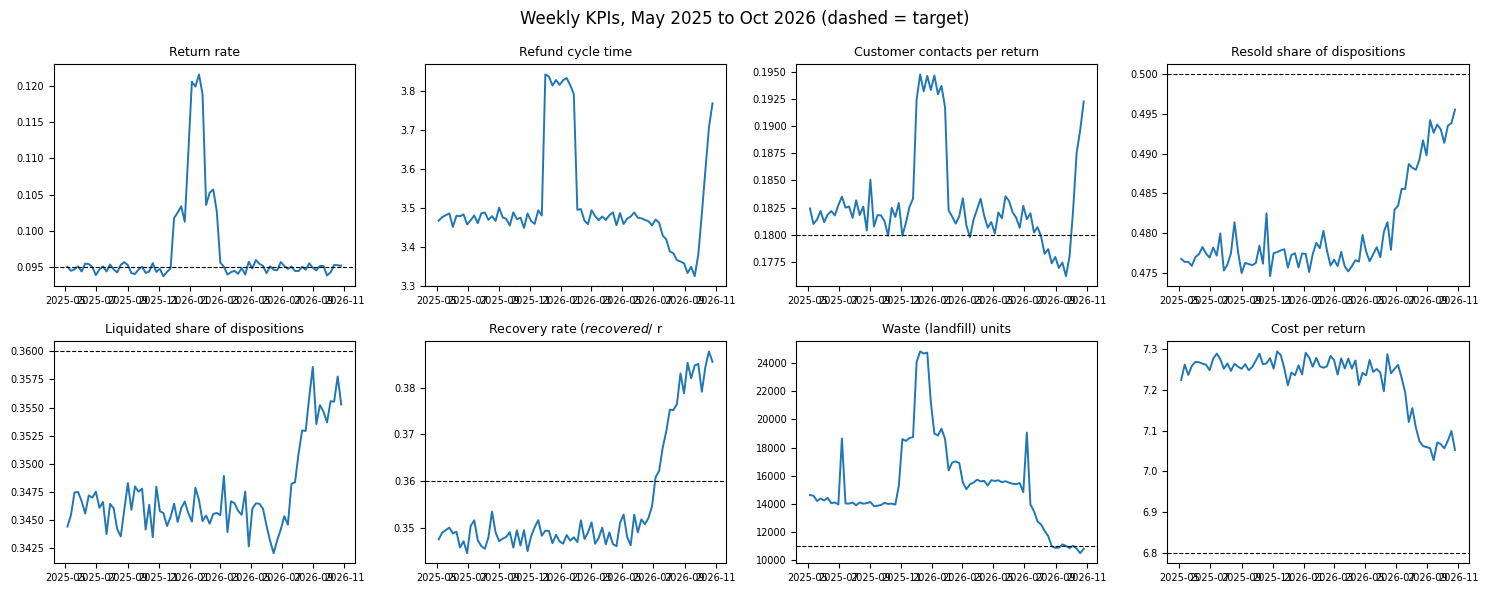

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(15, 6))
for ax, (_, t) in zip(axes.ravel(), targets.iterrows()):
    ax.plot(kpi.week_start, kpi[t.kpi], lw=1.4)
    ax.axhline(t.target, ls='--', color='k', lw=0.8)
    ax.set_title(t.display_name[:32], fontsize=9)
    ax.tick_params(labelsize=7)
fig.suptitle('Weekly KPIs, May 2025 to Oct 2026 (dashed = target)')
fig.tight_layout()

Quick seasonality check: return rate peaks in January (post-holiday returns), and refund cycle time rises in December and January when the warehouses are congested. A late-October jump in cycle time doesn't fit that pattern.

In [4]:
m = kpi.assign(month=kpi.week_start.dt.to_period('M')).groupby('month')[['return_rate', 'refund_cycle_days', 'contacts_per_return']].mean()
m.tail(18)

,return_rate,refund_cycle_days,contacts_per_return
month,,,
2025-05,0.0948,3.4769,0.1817
2025-06,0.0948,3.4693,0.1819
2025-07,0.0949,3.4732,0.1825
2025-08,0.0950,3.4749,0.1820
2025-09,0.0946,3.4776,0.1821
2025-10,0.0946,3.4693,0.1817
2025-11,0.0944,3.4741,0.1817
2025-12,0.1039,3.8262,0.1937
2026-01,0.1202,3.8157,0.1933


Waste share first 13 wks vs last 13 wks: 8.99% -> 6.69%


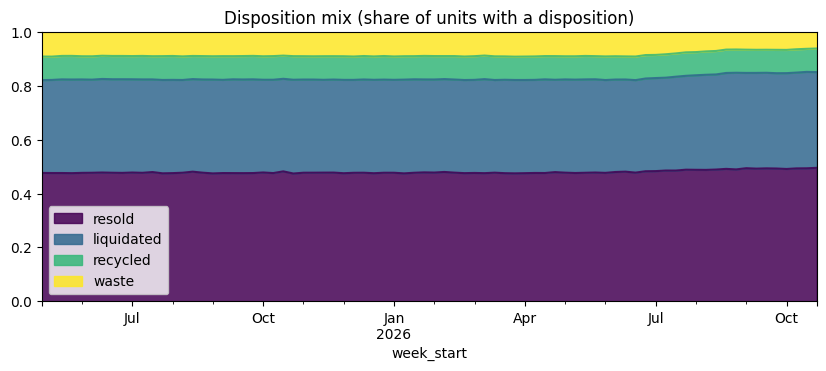

In [5]:
dispo = pd.read_sql('''SELECT week_start, SUM(resold_units) resold, SUM(liquidated_units) liquidated,
  SUM(recycled_units) recycled, SUM(waste_units) waste FROM weekly_fact GROUP BY week_start''', con, parse_dates=['week_start'])
sh = dispo.set_index('week_start')
sh = sh.div(sh.sum(axis=1), axis=0)
ax = sh.plot.area(figsize=(10, 3.5), cmap='viridis', alpha=0.85)
ax.set_title('Disposition mix (share of units with a disposition)'); ax.set_ylim(0, 1)
print('Waste share first 13 wks vs last 13 wks:', f"{sh.waste.head(13).mean():.2%} -> {sh.waste.tail(13).mean():.2%}")

## 2. Measure: detect the shift with a control chart

Baseline = 26 non-holiday weeks (2026-03-02 to 2026-08-24). Control limits = mean +/- 3 standard deviations of the weekly values.

baseline mean 3.454 d, sd 0.038, UCL 3.569
first week above UCL: 2026-10-12


,week_start,refund_cycle_days,contacts_per_return,above_ucl
69,2026-08-31,3.3570,0.1779,False
70,2026-09-07,3.3322,0.1769,False
71,2026-09-14,3.3481,0.1774,False
72,2026-09-21,3.3241,0.1762,False
73,2026-09-28,3.3790,0.1780,False
74,2026-10-05,3.4833,0.1822,False
75,2026-10-12,3.5954,0.1875,True
76,2026-10-19,3.7048,0.1896,True
77,2026-10-26,3.7672,0.1923,True


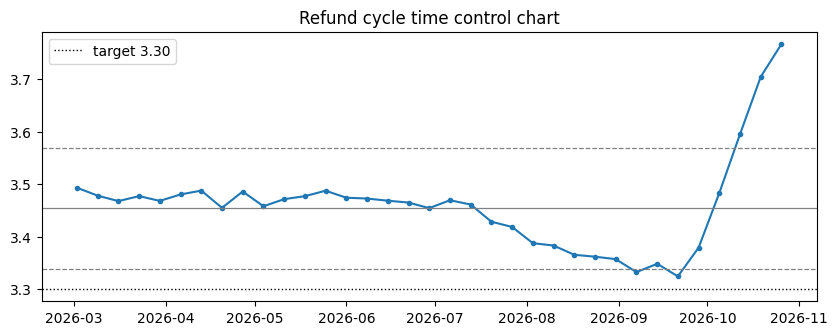

In [6]:
base = kpi[(kpi.week_start >= '2026-03-02') & (kpi.week_start <= '2026-08-24')]
mu, sd = base.refund_cycle_days.mean(), base.refund_cycle_days.std()
ucl, lcl = mu + 3 * sd, mu - 3 * sd
recent = kpi[kpi.week_start >= '2026-08-31'][['week_start', 'refund_cycle_days', 'contacts_per_return']].copy()
recent['above_ucl'] = recent.refund_cycle_days > ucl
print(f'baseline mean {mu:.3f} d, sd {sd:.3f}, UCL {ucl:.3f}')
first_signal = recent.loc[recent.above_ucl, 'week_start'].min()
print('first week above UCL:', first_signal.date())
fig, ax = plt.subplots(figsize=(10, 3.5))
w = kpi[kpi.week_start >= '2026-03-02']
ax.plot(w.week_start, w.refund_cycle_days, marker='o', ms=3)
for y, s in [(mu, '-'), (ucl, '--'), (lcl, '--')]: ax.axhline(y, ls=s, color='grey', lw=0.9)
ax.axhline(3.30, color='k', ls=':', lw=1, label='target 3.30')
ax.set_title('Refund cycle time control chart'); ax.legend()
recent

## 3. Analyze: which segment, rate or mix, transit or processing?

`sql/05_refund_cycle_driver_channel.sql` decomposes the change between a 4-week pre-incident baseline (weeks starting 2026-08-31 to 2026-09-21) and the report week into a **rate effect** (a segment got slower) and a **mix effect** (volume moved to a slower channel). The two effects sum exactly to the program change.

In [7]:
sql = (ROOT / 'sql' / '05_refund_cycle_driver_channel.sql').read_text()
drv = pd.read_sql(sql, con, params={'week_start': WEEK})
print(f"program change: {drv.total_effect_days.sum():+.3f} days (rate {drv.rate_effect_days.sum():+.3f}, mix {drv.mix_effect_days.sum():+.3f})")
drv.head(6)[['marketplace', 'channel', 'share_cur', 'days_base', 'days_cur', 'transit_change', 'processing_change', 'rate_effect_days', 'mix_effect_days', 'total_effect_days']]

program change: +0.427 days (rate +0.433, mix -0.006)


,marketplace,channel,share_cur,days_base,days_cur,transit_change,processing_change,rate_effect_days,mix_effect_days,total_effect_days
0,US,Mail-in,0.2017,4.0800,6.2748,2.2215,-0.0267,0.4426,-0.0022,0.4404
1,UK,Drop-off,0.0524,2.6184,2.6349,0.0074,0.0090,0.0009,0.0028,0.0037
2,UK,Carrier Pickup,0.0487,3.3476,3.3360,-0.0442,0.0327,-0.0006,0.0036,0.0030
3,DE,Carrier Pickup,0.0420,3.4359,3.4352,-0.0265,0.0259,-0.0000,0.0022,0.0022
4,UK,Mail-in,0.0874,4.1587,4.2307,0.0612,0.0108,0.0063,-0.0042,0.0021
5,CA,Carrier Pickup,0.0253,3.5903,3.5369,-0.0569,0.0035,-0.0013,0.0029,0.0016


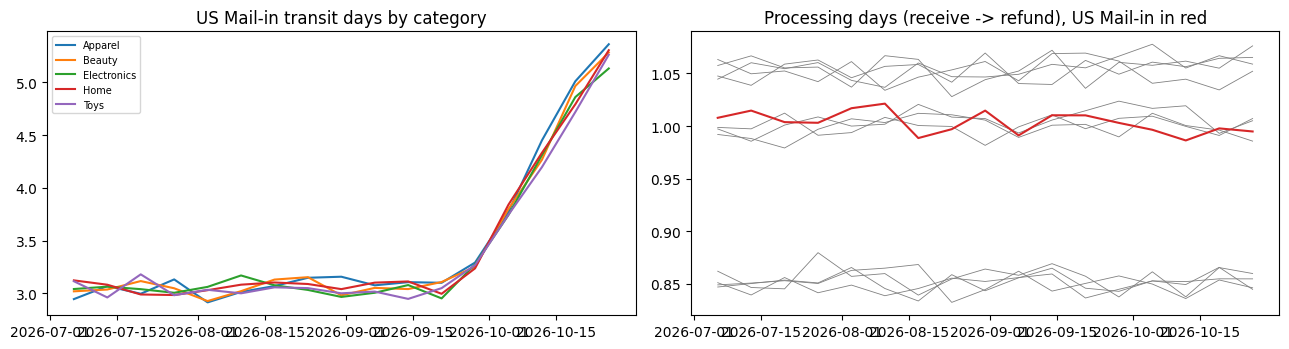

In [8]:
seg = pd.read_sql('''SELECT week_start, marketplace, channel, category,
  SUM(transit_hours)/24.0/SUM(cycle_units) transit_days, SUM(processing_hours)/24.0/SUM(cycle_units) processing_days
  FROM weekly_fact WHERE week_start >= '2026-07-06' AND channel <> 'Returnless'
  GROUP BY 1,2,3,4''', con, parse_dates=['week_start'])
us_mail = seg[(seg.marketplace == 'US') & (seg.channel == 'Mail-in')]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for c, g in us_mail.groupby('category'): axes[0].plot(g.week_start, g.transit_days, label=c)
axes[0].set_title('US Mail-in transit days by category'); axes[0].legend(fontsize=7)
for (mk, ch), g in seg.groupby(['marketplace', 'channel']):
    g2 = g.groupby('week_start')[['processing_days']].mean()
    axes[1].plot(g2.index, g2.processing_days, lw=1.5 if (mk, ch) == ('US', 'Mail-in') else 0.6, color='C3' if (mk, ch) == ('US', 'Mail-in') else 'grey')
axes[1].set_title('Processing days (receive -> refund), US Mail-in in red'); fig.tight_layout()

So the rise sits in one segment (US Mail-in), shows up in every category inside it, and it's transit (customer hand-off to warehouse receipt), not warehouse processing. That points at the carrier network change logged as ISS-005 / R05 (linehaul consolidation) rather than the returns centers. Mix effects are close to zero, so the drop-off expansion isn't pushing volume into slow channels.

## 4. Analyze: customer impact (contacts per return vs cycle time)

In [9]:
ols = smf.ols('contacts_per_return ~ refund_cycle_days', data=kpi).fit()
print(ols.summary().tables[1])
slope = ols.params['refund_cycle_days']
cur = kpi.set_index('week_start').loc[WEEK]
base_days = cur.refund_cycle_days - drv.total_effect_days.sum()
excess_contacts = slope * (cur.refund_cycle_days - base_days) * cur.return_units
print(f'R^2 {ols.rsquared:.2f}; each extra day of refund cycle = {slope:+.4f} contacts per return')
print(f'excess contacts in report week attributable to the cycle-time rise: {excess_contacts:,.0f}')

                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
Intercept             0.0642      0.003     22.927      0.000       0.059       0.070
refund_cycle_days     0.0339      0.001     42.470      0.000       0.032       0.035
R^2 0.96; each extra day of refund cycle = +0.0339 contacts per return
excess contacts in report week attributable to the cycle-time rise: 2,611


## 5. Improve: sized options

* Option A fixes the cause: get US Mail-in transit back to baseline through the carrier SLA review (M305) and escalate R05, which still has no mitigation owner.
* Option B protects customers while A lands: refund low-risk US Mail-in customers at the first carrier scan (the same pattern returnless refunds already use). They then wait only for the scan, not the linehaul. The Risk partner has to sign off on an abuse guardrail first.
* Option C is the structural one: unblock drop-off Wave 2 (M304), which is waiting on the QR label API (M402).

For the dollar sizing I assumed $4.50 handling cost per customer contact. That's a placeholder, not a measured number, and should be swapped for the finance partner's rate.

In [10]:
COST_PER_CONTACT = 4.50  # planning assumption
top = drv.sort_values('total_effect_days', ascending=False).iloc[0]
cycle_if_restored = cur.refund_cycle_days - top.total_effect_days
# Option B: US Mail-in customers refunded at carrier scan -> their wait = processing at origin scan ~ 0.25 d (returnless-like)
us_share = top.share_cur
cycle_if_scan_refund = cur.refund_cycle_days - us_share * (top.days_cur - 0.25)
weekly_contact_cost = excess_contacts * COST_PER_CONTACT
out = pd.DataFrame([
    ['report_week', WEEK],
    ['refund_cycle_days_current', round(cur.refund_cycle_days, 4)],
    ['refund_cycle_target', 3.30],
    ['baseline_cycle_days_program', round(base_days, 4)],
    ['program_change_days', round(drv.total_effect_days.sum(), 4)],
    ['top_driver_segment', f'{top.marketplace} {top.channel}'],
    ['top_driver_effect_days', round(top.total_effect_days, 4)],
    ['top_driver_days_base', round(top.days_base, 4)],
    ['top_driver_days_cur', round(top.days_cur, 4)],
    ['top_driver_transit_change_days', round(top.transit_change, 4)],
    ['top_driver_processing_change_days', round(top.processing_change, 4)],
    ['top_driver_volume_share', round(top.share_cur, 4)],
    ['control_chart_ucl_days', round(ucl, 4)],
    ['first_week_above_ucl', str(first_signal.date())],
    ['contacts_per_day_slope', round(slope, 4)],
    ['ols_r2', round(ols.rsquared, 4)],
    ['excess_contacts_week', round(excess_contacts)],
    ['assumed_cost_per_contact_usd', COST_PER_CONTACT],
    ['excess_contact_cost_week_usd', round(weekly_contact_cost)],
    ['excess_contact_cost_annualized_usd', round(weekly_contact_cost * 52)],
    ['cycle_days_if_us_mailin_restored', round(cycle_if_restored, 4)],
    ['cycle_days_if_us_mailin_refund_at_scan', round(cycle_if_scan_refund, 4)],
], columns=['metric', 'value'])
out.to_csv(OUT / 'driver_analysis_summary.csv', index=False)
out

,metric,value
0,report_week,2026-10-26
1,refund_cycle_days_current,3.7672
2,refund_cycle_target,3.3000
3,baseline_cycle_days_program,3.3404
4,program_change_days,0.4268
5,top_driver_segment,US Mail-in
6,top_driver_effect_days,0.4404
7,top_driver_days_base,4.0800
8,top_driver_days_cur,6.2748
9,top_driver_transit_change_days,2.2215


## 6. Control

* Add the control-chart rule to the WBR: flag any week above the UCL for refund cycle time at the marketplace x channel grain. A single-segment shift would then show up in week 1 instead of after the program KPI has already crossed target.
* Track transit and processing days separately in the dashboard (calculated fields in `dashboard/dashboard_spec.md`).
* Keep R05 on the WBR risk table until US Mail-in transit is back within the baseline control limits for 2 consecutive weeks.

In [11]:
con.close()